# 17 · LLM and lexical methods on the Stelmakh et al. gold standard

**Question.** On citation labels, listwise Llama 3.2 3B mostly copies the candidate order and LLM reranking does not beat the embedding first stage. Does that hold when the label is a researcher's own rating of their reviewing expertise (Stelmakh et al., 58 participants, 477 ratings)?

Data card: `audit/GOLDSTANDARD_DATA.md`. Module: `src/goldstandard.py` (tests in `tests/test_goldstandard.py`); metric and bootstrap: `src/bibcoupling.py`. The LLM calls are run by `python -m src.goldstandard listwise|pointwise|reranker GOLDSTANDARD_DIR` and cached per call in `data/v2/goldstandard_llm/`; this notebook only reads the caches unless `RUN = True`.

## Design (committed in code before any LLM loss was computed)

Not a strict pre-registration: the lexical losses and the call statuses of two timing probes (one participant with the citation prompt, ten with the expertise prompt) were seen before this cell was written.

There is no dev split, so nothing below is tuned.

- **Prompts.** The label is reviewing expertise, so the prompts ask "how qualified is this researcher to review the candidate", not "will it be cited". The structure is the v2 one: a numbered candidate list and a JSON array answer (listwise); a single 0–10 integer scored from the first-token logprobs (pointwise); P(yes) with an instruction (Qwen3-Reranker-4B, model-card implementation). Texts: candidate title + abstract cut at 600 characters, reranker query at 1,500, as in v2.
- **Researcher representation.** Listwise and pointwise Llama see the profile sample's **titles** (up to 20). Qwen3-Reranker uses **each profile paper (title + abstract) as the query** and takes the max over the profile, as the embeddings do (data card, items 2 and 4).
- **Listwise orders.** Per participant, all rated papers (3–10) in one list, shown **shuffled**, **best-first** or **worst-first** by true rating (ties broken by a seeded shuffle). Seeds 1–5; seed *s* uses profile sample d_20_*s*, so the five seeds also vary the profile. On a parse failure the order is random, never the shown order; unranked papers go last in random order. Predicted score = list length − position.
- **Lexical.** BM25 (Okapi, `rank_bm25` defaults) and TF-IDF cosine on title + abstract; tokens = lower-case alphanumeric runs minus sklearn's English stop words; IDF fitted on all texts of the profile sample. Each profile paper is a query, the rated papers are documents, max over the profile.
- **Metric.** The official weighted Kendall-tau loss (lower is better, constant = 0.5), mean over the profile samples a method was run on, with the seeded participant bootstrap (`bc.bootstrap_ci`, 1,000 pools, seed 0).
- **Tests.** Per-participant loss averaged over the same samples for both methods; paired Wilcoxon; Holm within a family.
  - Family 1, each method vs Qwen3-Embedding-8B (max, notebook 14 predictions), restricted to the method's samples.
  - Family 2, listwise order contrasts: best-first vs shuffled, worst-first vs shuffled, best-first vs worst-first.

In [1]:
GOLDSTANDARD_DIR = ""   # absolute path to the gold-standard clone; papermill -p, or env GOLDSTANDARD_DIR
RUN = False             # True: make any missing LLM calls (llama-server must be up; slow)
N_BOOT = 1000
SEED = 0

In [2]:
# Parameters
GOLDSTANDARD_DIR = "/Users/senaoz/Developer/SWE-599/research/data/external/goldstandard"


In [3]:
import json
import os
import sys
from pathlib import Path

RESEARCH = Path.cwd().parent if Path.cwd().name == "v2" else Path.cwd()
sys.path.insert(0, str(RESEARCH))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kendalltau, wilcoxon

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

from src import bibcoupling as bc
from src import goldstandard as gs
from src.figures import INK, INK_2, SLOTS, save, setup_style
from src.stats_v2 import holm

G = Path(GOLDSTANDARD_DIR or os.environ["GOLDSTANDARD_DIR"])
CACHE = RESEARCH / "data" / "v2" / "goldstandard_llm"
OUT = RESEARCH / "v2" / "goldstandard"
PRED_DIR = OUT / "predictions"
SAMPLES = list(gs.SAMPLES)

data = gs.load(G)
refs, REVIEWERS = data["refs"], sorted(data["refs"])
print(f"participants {len(REVIEWERS)}, ratings {sum(map(len, refs.values()))}")

participants 58, ratings 477


## Methods without LLM calls

In [4]:
preds, samples_of = {}, {}   # method -> list of preds per sample; method -> sample numbers
def add(name, P, samples):
    preds[name], samples_of[name] = P, list(samples)

add("qwen", [json.load(open(PRED_DIR / f"qwen_d_20_{i}_ta.json")) for i in SAMPLES], SAMPLES)
add("specter2", [json.load(open(PRED_DIR / f"specter2_d_20_{i}_ta.json")) for i in SAMPLES], SAMPLES)
add("bm25", gs.lexical_preds(data, "bm25"), SAMPLES)
add("tfidf", gs.lexical_preds(data, "tfidf"), SAMPLES)
add("constant", [{rv: {p: 0.0 for p in refs[rv]} for rv in REVIEWERS} for _ in SAMPLES], SAMPLES)

## Listwise Llama 3.2 3B under three orders

In [5]:
if RUN:
    gs.run_listwise(data, CACHE)
SEEDS = list(gs.LISTWISE_SEEDS)
calls = pd.DataFrame([r for o in gs.ORDERS for s in SEEDS for r in gs.read_listwise(CACHE, o, s)])
assert len(calls) == len(gs.ORDERS) * len(SEEDS) * len(REVIEWERS), "listwise cache incomplete"
calls["n"] = calls.shown.map(len)
calls["copied"] = [r.status == "ok" and r.ranked == r.shown for r in calls.itertuples()]
calls["tau_shown"] = [kendalltau(range(r.n), [r.shown.index(p) for p in r.ranked]).statistic for r in calls.itertuples()]
summary = calls.groupby("order").agg(calls=("status", "size"), ok=("status", lambda s: (s == "ok").mean()),
                                     partial=("status", lambda s: (s == "partial").mean()),
                                     failed=("status", lambda s: s.isin(["parse_fail", "http_error"]).mean()),
                                     copied_exactly=("copied", "mean"), mean_tau_with_shown_order=("tau_shown", "mean"),
                                     prompt_tokens_max=("prompt_tokens", "max")).loc[list(gs.ORDERS)]
print("status counts:", calls.status.value_counts().to_dict())
summary.round(3)

status counts: {'ok': 867, 'partial': 3}


,calls,ok,partial,failed,copied_exactly,mean_tau_with_shown_order,prompt_tokens_max
order,,,,,,,
shuffled,290,0.993,0.007,0.0,0.345,0.315,1654
best_first,290,1.000,0.000,0.0,0.424,0.433,1654
worst_first,290,0.997,0.003,0.0,0.345,0.279,1654


In [6]:
def listwise_preds(order):
    out = []
    for s in SEEDS:
        rows = calls[(calls.order == order) & (calls.seed == s)]
        out.append({r.reviewer: {p: float(r.n - k) for k, p in enumerate(r.ranked)} for r in rows.itertuples()})
    return out

for o in gs.ORDERS:
    add(f"listwise_{o}", listwise_preds(o), SEEDS)

## Pointwise Llama 3.2 3B and Qwen3-Reranker-4B

In [7]:
if RUN:
    gs.run_llama(data, CACHE)
llama = gs.llama_cache(CACHE)
done = [i for i in SAMPLES if all((f"{rv}|d_20_{i}", p) in llama.scores for rv in REVIEWERS for p in refs[rv])]
if done:
    add("pointwise_llama", [{rv: dict(zip(sorted(refs[rv]), llama.get(f"{rv}|d_20_{i}", sorted(refs[rv])).tolist()))
                             for rv in REVIEWERS} for i in done], done)
    st = pd.Series([llama.scores[(f"{rv}|d_20_{i}", p)]["status"] for i in done for rv in REVIEWERS for p in refs[rv]])
    print(f"pointwise Llama: samples {done}, status {st.value_counts().to_dict()}")
else:
    print("pointwise Llama: no complete sample cached")

pointwise Llama: samples [1, 2, 3, 4, 5, 6, 7, 8, 9, 10], status {'ok': 4770}


In [8]:
if RUN:
    gs.run_reranker(data, CACHE)
rr = gs.reranker_cache(CACHE)
pairs = gs.reranker_pairs(data)
missing = sum((q, p) not in rr.scores for q, docs in pairs.items() for p in docs)
if missing == 0:
    add("qwen3_reranker", gs.max_preds(data, rr), SAMPLES)
    st = pd.Series([rr.scores[(q, p)]["status"] for q, docs in pairs.items() for p in docs])
    print(f"Qwen3-Reranker: {len(st)} pairs, status {st.value_counts().to_dict()}")
else:
    print(f"Qwen3-Reranker: {missing} of {sum(map(len, pairs.values()))} pairs not scored; not reported")

Qwen3-Reranker: 7573 pairs, status {'ok': 7573}


## Results

In [9]:
NAMES = {"qwen": "Qwen3-Embedding-8B (max)", "specter2": "SPECTER2 [CLS] (max)", "bm25": "BM25 (max)",
         "tfidf": "TF-IDF (max)", "listwise_shuffled": "Listwise Llama, shuffled",
         "listwise_best_first": "Listwise Llama, best-first", "listwise_worst_first": "Listwise Llama, worst-first",
         "pointwise_llama": "Pointwise Llama (profile titles)", "qwen3_reranker": "Qwen3-Reranker-4B (max)",
         "constant": "Constant"}
rows = []
for name, P in preds.items():
    point, lo, hi = bc.bootstrap_ci(P, refs, N_BOOT, SEED)
    q = [preds["qwen"][i - 1] for i in samples_of[name]]
    rows.append({"method": name, "samples": ",".join(map(str, samples_of[name])), "loss": point, "lo": lo, "hi": hi,
                 "qwen on same samples": bc.bootstrap_ci(q, refs, N_BOOT, SEED)[0]})
results = pd.DataFrame(rows).set_index("method")
results.round(3)

,samples,loss,lo,hi,qwen on same samples
method,,,,,
qwen,"1,2,3,4,5,6,7,8,9,10",0.222,0.177,0.274,0.222
specter2,"1,2,3,4,5,6,7,8,9,10",0.231,0.183,0.282,0.222
bm25,"1,2,3,4,5,6,7,8,9,10",0.275,0.216,0.331,0.222
tfidf,"1,2,3,4,5,6,7,8,9,10",0.289,0.233,0.349,0.222
constant,"1,2,3,4,5,6,7,8,9,10",0.500,0.500,0.500,0.222
listwise_shuffled,"1,2,3,4,5",0.467,0.442,0.493,0.222
listwise_best_first,"1,2,3,4,5",0.253,0.179,0.328,0.222
listwise_worst_first,"1,2,3,4,5",0.685,0.604,0.765,0.222
pointwise_llama,"1,2,3,4,5,6,7,8,9,10",0.337,0.282,0.395,0.222


## Paired tests (per-participant loss, Wilcoxon, Holm)

In [10]:
def per_participant(name, samples):
    per = [bc.per_reviewer_loss(preds[name][samples_of[name].index(i)], refs) for i in samples]
    return pd.Series({rv: np.mean([d[rv] for d in per]) for rv in per[0]})

def test_family(pairs):
    out = []
    for a, b in pairs:
        S = [i for i in samples_of[a] if i in samples_of[b]]
        la, lb = per_participant(a, S), per_participant(b, S)
        diff = la - lb
        stat, p = wilcoxon(la, lb) if (diff != 0).any() else (np.nan, 1.0)
        out.append({"a": a, "b": b, "samples": len(S), "mean loss a": la.mean(), "mean loss b": lb.mean(),
                    "mean diff (a-b)": diff.mean(), "a better": int((diff < 0).sum()),
                    "b better": int((diff > 0).sum()), "ties": int((diff == 0).sum()), "W": stat, "p": p})
    t = pd.DataFrame(out)
    t["p_holm"] = holm(t["p"].tolist())
    return t

fam1 = [(m, "qwen") for m in ("bm25", "tfidf", "listwise_shuffled", "pointwise_llama", "qwen3_reranker") if m in preds]
fam2 = [("listwise_best_first", "listwise_shuffled"), ("listwise_worst_first", "listwise_shuffled"),
        ("listwise_best_first", "listwise_worst_first")]
t1, t2 = test_family(fam1), test_family(fam2)
t1["family"], t2["family"] = 1, 2
tests = pd.concat([t1, t2], ignore_index=True)
show = tests.copy()
num = [c for c in show.columns if c.startswith(("mean", "W"))]
show[num] = show[num].round(3)
show[["p", "p_holm"]] = show[["p", "p_holm"]].map(lambda x: f"{x:.2e}")   # p-values never rounded to 0
show

,a,b,samples,mean loss a,mean loss b,mean diff (a-b),a better,b better,ties,W,p,p_holm,family
0,bm25,qwen,10,0.309,0.256,0.053,20,33,5,425.0,1.01e-02,1.01e-02,1
1,tfidf,qwen,10,0.338,0.256,0.083,17,38,3,370.0,8.04e-04,2.41e-03,1
2,listwise_shuffled,qwen,5,0.472,0.255,0.216,12,45,1,130.0,3.13e-08,1.57e-07,1
3,pointwise_llama,qwen,10,0.374,0.256,0.119,13,43,2,320.0,9.66e-05,3.86e-04,1
4,qwen3_reranker,qwen,10,0.317,0.256,0.062,15,39,4,414.0,4.68e-03,9.35e-03,1
5,listwise_best_first,listwise_shuffled,5,0.302,0.472,-0.169,40,18,0,368.0,1.60e-04,1.82e-04,2
6,listwise_worst_first,listwise_shuffled,5,0.636,0.472,0.164,16,42,0,350.0,9.09e-05,1.82e-04,2
7,listwise_best_first,listwise_worst_first,5,0.302,0.636,-0.333,43,14,1,251.0,4.81e-06,1.44e-05,2


## Figure and outputs

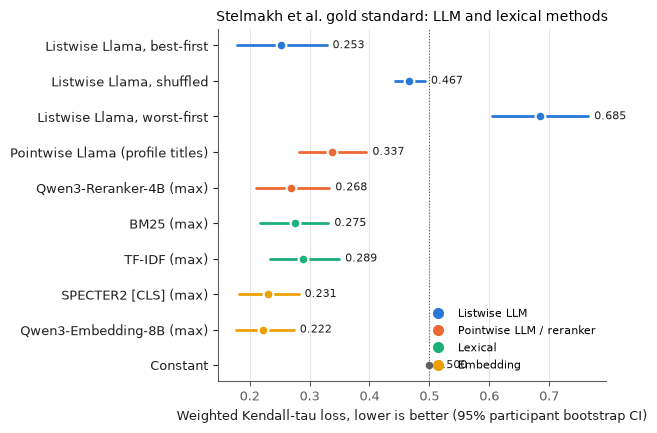

In [11]:
setup_style()
order = [m for m in ["listwise_best_first", "listwise_shuffled", "listwise_worst_first", "pointwise_llama",
                     "qwen3_reranker", "bm25", "tfidf", "specter2", "qwen", "constant"] if m in results.index]
grp = lambda m: 0 if m.startswith("listwise") else 1 if m in ("pointwise_llama", "qwen3_reranker") \
      else 2 if m in ("bm25", "tfidf") else 3
t = results.loc[order[::-1]]
fig, ax = plt.subplots(figsize=(6.4, 0.32 * len(t) + 1.2))
for y, (m, r) in enumerate(t.iterrows()):
    c = SLOTS[grp(m)] if m != "constant" else INK_2
    ax.plot([r.lo, r.hi], [y, y], color=c, lw=2, solid_capstyle="round")
    ax.plot(r.loss, y, "o", color=c, mec="white", mew=1.5)
    ax.text(r.hi + 0.01, y, f"{r.loss:.3f}", va="center", fontsize=8, color=INK)
ax.set_yticks(range(len(t)), [NAMES[m] for m in t.index])
ax.axvline(0.5, color=INK_2, lw=0.8, ls=":")
ax.set_xlabel("Weighted Kendall-tau loss, lower is better (95% participant bootstrap CI)")
ax.set_title("Stelmakh et al. gold standard: LLM and lexical methods"); ax.grid(axis="y", visible=False)
handles = [plt.Line2D([], [], marker="o", ls="", color=SLOTS[i], label=l)
           for i, l in enumerate(["Listwise LLM", "Pointwise LLM / reranker", "Lexical", "Embedding"])]
ax.legend(handles=handles, loc="lower right", fontsize=8)
fig.tight_layout()
save(fig, "17_llm_goldstandard")

In [12]:
for name in [m for m in preds if m not in ("qwen", "specter2", "constant")]:
    algo = name.replace("_", "-")
    for i, P in zip(samples_of[name], preds[name]):
        with open(PRED_DIR / f"{algo}_d_20_{i}_ta.json", "w") as f:
            json.dump(P, f)
results.reset_index().to_csv(OUT / "17_results.csv", index=False, float_format="%.6g")
tests.to_csv(OUT / "17_tests.csv", index=False, float_format="%.6g")
summary.reset_index().to_csv(OUT / "17_listwise_calls.csv", index=False, float_format="%.6g")
print("written:", sorted(p.name for p in OUT.glob("17_*.csv")))

written: ['17_listwise_calls.csv', '17_results.csv', '17_tests.csv']


### Findings

- **Runs.** Listwise: 870 calls, 867 ok, 3 partial, 0 failed (largest prompt 1,654 tokens). Pointwise Llama: 4,770 calls, all ok, all scored from logprobs. Qwen3-Reranker-4B: 7,573 unique (profile paper, rated paper) pairs, all ok; 5.4 h (about 2.6 s per pair, against the 0.46–0.86 s seen in notebook 12).
- **No LLM method beats Qwen3-Embedding-8B (0.222 [0.177, 0.274]) on human labels.** Every one is significantly worse (family 1, Holm): Qwen3-Reranker-4B 0.268 [0.210, 0.333] (p_holm = 9.4e-03), pointwise Llama 0.337 [0.282, 0.395] (3.9e-04), listwise Llama, shuffled 0.467 [0.442, 0.493] (1.6e-07). BM25 0.275 and TF-IDF 0.289 are also worse (1.0e-02, 2.4e-03).
- **Position bias replicates.** Listwise Llama's loss moves with the shown order: best-first 0.253, shuffled 0.467, worst-first 0.685 (all three contrasts Holm p ≤ 1.8e-04; best- vs worst-first 43 vs 14 participants). Shuffled, the model is barely better than the constant (0.5); its output keeps the shown order exactly in 35% of lists (mean Kendall τ with the shown order 0.32). Best-first is close to Qwen3 only because the true order was given.
- **Reading the tests table.** "mean loss" there is the mean of per-participant losses (Qwen3 0.256), which weighs participants equally; the results table uses the official pooled loss.
- **Limits.** Listwise uses samples 1–5 (one per seed) and its Qwen3 comparison is restricted to those; CS/ML only; every rated paper predates the model cutoffs.
